# 9 · Temporal-difference control

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shimmeringvoid/MDP_Experiments/blob/main/notebooks/09_td_control.ipynb)

Q-learning was the report's only learner. It is one member of a family of methods that learn
action values from sampled transitions, and the family's other members answer questions that
Q-learning alone cannot raise. This notebook runs four of them on the report's grid world:

* **Q-learning**, which learns about the greedy policy whatever the agent actually does;
* **SARSA** and **Expected SARSA**, which learn about the policy the agent is following,
  exploration included;
* **Double Q-learning**, which keeps two tables to avoid Q-learning's optimistic bias;

and then two ways of using a *model* that the agent builds from its own experience:

* **Dyna-Q**, which replays remembered transitions between real moves;
* **planning on the estimated model**, the model-based use of the very samples the 2014
  Q-learner was given.

In [ ]:
# Only needed on Google Colab, which opens this notebook without the rest of the repository:
# fetch the repository and put its library on the path.  Anywhere else this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    if not os.path.isdir("MDP_Experiments"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/shimmeringvoid/MDP_Experiments"], check=True)
    sys.path.insert(0, os.path.abspath("MDP_Experiments/src"))

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp

mp.use_style()
pd.options.display.float_format = "{:,.2f}".format

world = ml.GridWorld.report_figure1()
mdp = world.mdp
free = world.free
S, A = mdp.n_states, mdp.n_actions
scorer = ml.PolicyScorer(mdp)
EPS = 0.1

## Four learners, one world

All four act ϵ-greedily with ϵ = 0.1, use a constant step size of 0.1 and start every episode in
a random cell. Ten agents of each kind are trained for 300,000 moves. As in notebook 5, a learner
is scored by the exact value its greedy policy gives up against the optimum.

62 s


,"value given up after 300,000 moves","value given up, average over the last third"
Q-learning,0.03,0.16
Expected SARSA,2.15,1.51
SARSA,48.77,35.94
Double Q-learning,52.67,57.76


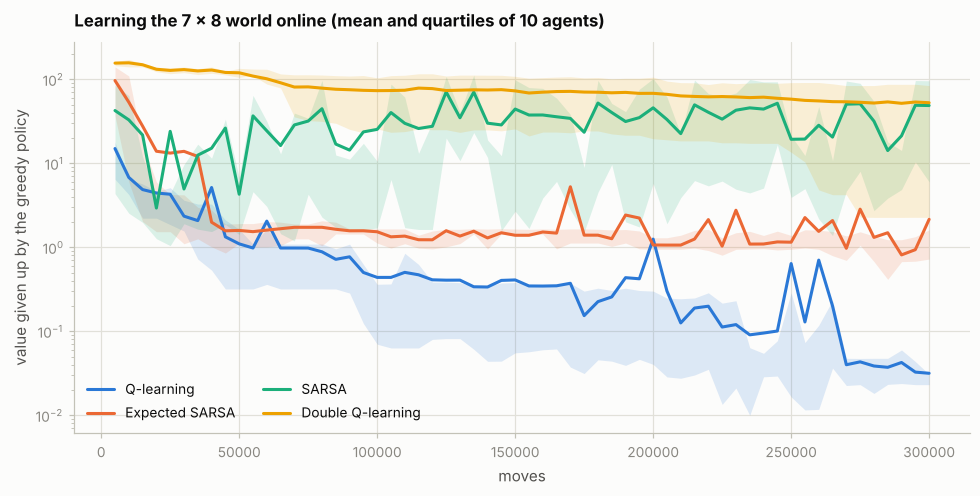

In [2]:
methods = {"q_learning": "Q-learning", "expected_sarsa": "Expected SARSA", "sarsa": "SARSA", "double_q": "Double Q-learning"}
agents = {}
start = time.perf_counter()
for method in methods:
    agents[method] = ml.td_control(mdp, 300_000, method=method, epsilon=EPS, alpha=0.1, n_runs=10, seed=9,
                                   scorer=scorer, n_checkpoints=60, max_episode_steps=1000)
print(f"{time.perf_counter() - start:.0f} s")

fig, ax = plt.subplots(figsize=(8.8, 4.4))
for (method, label), colour in zip(methods.items(), mp.SERIES):
    run = agents[method]
    mp.band(ax, run.steps, np.maximum(run.history["value_gap"], 1e-2), color=colour, label=label, center="mean")
ax.set(yscale="log", xlabel="moves", ylabel="value given up by the greedy policy", title="Learning the 7 × 8 world online (mean and quartiles of 10 agents)")
ax.legend(loc="lower left", ncol=2)
mp.savefig(fig, "09_four_learners")

pd.DataFrame(
    {label: {"value given up after 300,000 moves": agents[m].history["value_gap"][-1].mean(),
             "value given up, average over the last third": agents[m].history["value_gap"][-20:].mean()} for m, label in methods.items()}
).T

Q-learning gets closest to the optimal policy, Expected SARSA settles a little above it, SARSA
never settles at all, and Double Q-learning is still far away and descending slowly. Each of these
has a reason, and the first two are the same reason seen from two sides.

## What is the agent being asked to be good at?

Q-learning's target assumes that from the next state on the agent will act greedily. The SARSA
family's target assumes that it will go on acting as it does now, with one move in ten chosen at
random. These are different problems with different answers, and the grid world of the report
makes the difference unusually vivid.

The second problem can be solved exactly. An agent that always picks a random move with
probability ϵ lives, in effect, in a world with more slippery transitions, and that world is just
another MDP.

,executed exactly,executed with ϵ = 0.1
best policy for a steady hand,182.16,164.93
best policy for a shaky hand,180.84,166.06


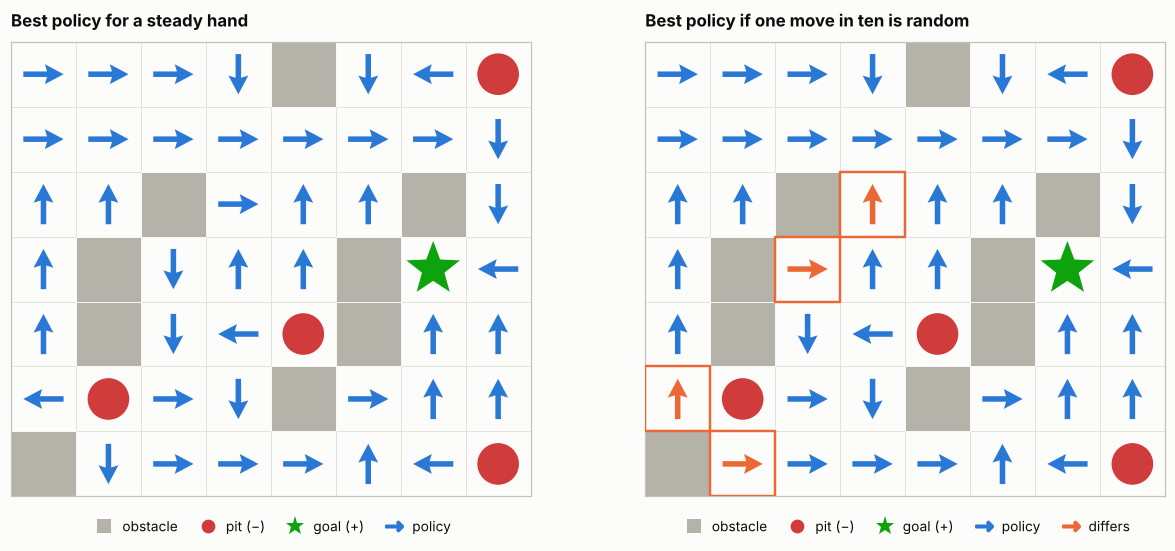

In [3]:
P = mdp.P.toarray().reshape(S, A, S)
trembling = ml.MDP(
    P=((1 - EPS) * P + EPS * P.mean(axis=1, keepdims=True)).reshape(S * A, S),
    r_next=mdp.r_next, gamma=mdp.gamma, terminal=mdp.terminal, name="7 × 8 world for an agent that explores for ever",
)
steady = ml.policy_iteration(mdp).policy  # optimal if the policy is executed exactly
shaky = ml.policy_iteration(trembling).policy  # optimal if one move in ten is random


def soft(policy, eps):
    """The epsilon-greedy version of a deterministic policy, as a matrix of action probabilities."""
    pi = np.full((S, A), eps / A)
    pi[np.arange(S), policy] += 1 - eps
    return pi


def value(policy, eps):
    """Mean value over starting cells when the policy is executed with exploration rate eps."""
    return ml.evaluate_policy(mdp, soft(policy, eps) if eps else policy)[free].mean()


differ = free & (steady != shaky)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.9))
mp.plot_gridworld(world, steady, ax=axes[0], title="Best policy for a steady hand")
mp.plot_gridworld(world, shaky, flagged=differ, ax=axes[1], title="Best policy if one move in ten is random", flagged_label="differs")
mp.savefig(fig, "09_steady_and_shaky")

pd.DataFrame(
    {"executed exactly": [value(steady, 0), value(shaky, 0)], f"executed with ϵ = {EPS}": [value(steady, EPS), value(shaky, EPS)]},
    index=["best policy for a steady hand", "best policy for a shaky hand"],
)

The two policies differ in four cells, and two of them are old acquaintances: the cells in the
bottom-left corner where the optimal policy pushes against a wall and waits for a slip
(notebooks 1 and 2). Waiting is free of risk only for an agent with a steady hand. One that makes
a random move every tenth step, while standing next to a pit for ten steps, will fall in about one
time in five. For such an agent it is better to walk past the pit briskly and accept the
one-in-ten slip.

Each policy is the better one in its own regime, as the table shows. So the "scenic route" of the
report, the signature of its optimal policies, is the right answer to one question, and an agent
that keeps exploring is being asked another.

Now the learners can be read properly.

In [4]:
rows_out = []
for method, label in methods.items():
    policies = agents[method].policies
    rows_out.append({
        "learner": label,
        "value, executed exactly": np.mean([value(p, 0) for p in policies]),
        f"value, executed with ϵ = {EPS}": np.mean([value(p, EPS) for p in policies]),
        "agents that wait at (6, 1)": int((policies[:, world.state(6, 1)] == steady[world.state(6, 1)]).sum()),
        "agents that wait at (5, 0)": int((policies[:, world.state(5, 0)] == steady[world.state(5, 0)]).sum()),
    })
rows_out.append({"learner": "exact optimum, steady hand", "value, executed exactly": value(steady, 0), f"value, executed with ϵ = {EPS}": value(steady, EPS),
                 "agents that wait at (6, 1)": "yes", "agents that wait at (5, 0)": "yes"})
rows_out.append({"learner": "exact optimum, shaky hand", "value, executed exactly": value(shaky, 0), f"value, executed with ϵ = {EPS}": value(shaky, EPS),
                 "agents that wait at (6, 1)": "no", "agents that wait at (5, 0)": "no"})
learned = pd.DataFrame(rows_out).set_index("learner")
learned

,"value, executed exactly","value, executed with ϵ = 0.1","agents that wait at (6, 1)","agents that wait at (5, 0)"
learner,,,,
Q-learning,182.13,164.42,10,10
Expected SARSA,180.01,164.36,3,5
SARSA,133.39,129.08,1,1
Double Q-learning,129.49,118.44,2,4
"exact optimum, steady hand",182.16,164.93,yes,yes
"exact optimum, shaky hand",180.84,166.06,no,no


In [5]:
q, es = learned.loc["Q-learning"], learned.loc["Expected SARSA"]
display(Markdown(
    f"* Of the ten **Q-learning** agents, {q['agents that wait at (6, 1)']} wait at (6, 1) and {q['agents that wait at (5, 0)']} at (5, 0). "
    f"Executed exactly, their policies are worth {q['value, executed exactly']:.2f}; the optimum is {value(steady, 0):.2f}.\n"
    f"* Of the ten **Expected SARSA** agents, only {es['agents that wait at (6, 1)']} wait at (6, 1) and {es['agents that wait at (5, 0)']} at (5, 0). "
    f"Executed exactly, their policies are worth {es['value, executed exactly']:.2f}, "
    f"{q['value, executed exactly'] - es['value, executed exactly']:.1f} less than Q-learning's. "
    f"Executed with ϵ = {EPS} they are worth {es[f'value, executed with ϵ = {EPS}']:.2f} against Q-learning's {q[f'value, executed with ϵ = {EPS}']:.2f}."
))

* Of the ten **Q-learning** agents, 10 wait at (6, 1) and 10 at (5, 0). Executed exactly, their policies are worth 182.13; the optimum is 182.16.
* Of the ten **Expected SARSA** agents, only 3 wait at (6, 1) and 5 at (5, 0). Executed exactly, their policies are worth 180.01, 2.1 less than Q-learning's. Executed with ϵ = 0.1 they are worth 164.36 against Q-learning's 164.42.

* **Q-learning** learns the steady-hand policy and waits at the walls. Its policy is the best one
  to *deploy* with exploration switched off, and not the best one to live with while exploration
  is on.
* **Expected SARSA** leans the other way: most of its agents have given up waiting next to a pit.
  Much of its "shortfall" in the first figure is therefore not a failure to learn. It is the price
  of learning the answer to the other question. With a constant step size its estimates are still
  too noisy to turn that into a clear advantage under exploration; its policies come out about
  level with Q-learning's there, and short of what the exact shaky-hand optimum would earn.
* **SARSA** aims at the same target as Expected SARSA but uses the value of the one action it
  happens to take next, instead of the average over what it might take. Here that is a noisy
  target: every so often the next action is a random step into a pit, and a −200 lands in the
  update. With a constant step size the estimates never calm down, and the greedy policy keeps
  flipping. Averaging over the next action, which costs nothing extra, removes exactly this noise.
* **Double Q-learning** exists to cure Q-learning's tendency to overestimate, which comes from
  taking a maximum over noisy estimates. That is not this world's problem: notebook 5 found the
  learners here *under*estimating for most of their lives. Splitting the experience over two
  tables halves the data each one sees, and valuing one table's favourite action by the other's
  estimate is pessimistic whenever the second table has not caught up. Near pits, where a single
  bad estimate is worth −200, that pessimism is slow to wear off.

## Dyna-Q: replaying experience

Every transition the agent experiences is used once by Q-learning and then thrown away. Dyna-Q
keeps it. It counts where each state-action pair has led, and after every real move it performs a
number of extra updates on remembered pairs, sampling their outcomes from those counts. The model
is built entirely from the agent's own experience.

29 s


,"value given up after 10,000 moves","after 40,000 moves",moves until it first falls below 1
replayed updates per move,,,
0,7.18,1.26,"more than 40,000"
5,1.28,0.48,"13,000"
20,2.11,0.62,"13,000"
50,5.35,0.28,"16,000"


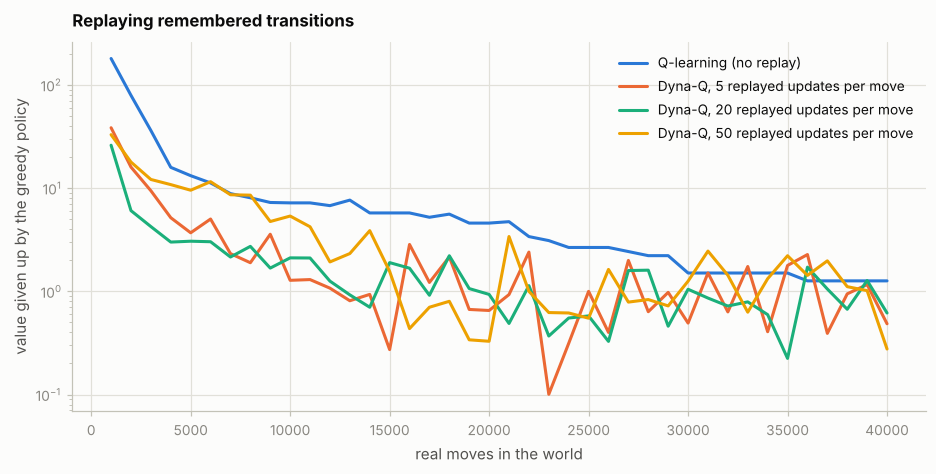

In [6]:
dyna = {}
start = time.perf_counter()
for n_planning in (0, 5, 20, 50):
    dyna[n_planning] = ml.td_control(mdp, 40_000, epsilon=EPS, alpha=0.1, planning_steps=n_planning, n_runs=10, seed=4,
                                     scorer=scorer, n_checkpoints=40, max_episode_steps=1000)
print(f"{time.perf_counter() - start:.0f} s")

fig, ax = plt.subplots(figsize=(8.4, 4.2))
for (n_planning, run), colour in zip(dyna.items(), mp.SERIES):
    label = "Q-learning (no replay)" if n_planning == 0 else f"Dyna-Q, {n_planning} replayed updates per move"
    ax.plot(run.steps, run.history["value_gap"].mean(axis=1), color=colour, label=label)
ax.set(yscale="log", xlabel="real moves in the world", ylabel="value given up by the greedy policy", title="Replaying remembered transitions")
ax.legend()
mp.savefig(fig, "09_dyna")

rows_out = {}
for n_planning, run in dyna.items():
    gap = run.history["value_gap"].mean(axis=1)
    rows_out[n_planning] = {"value given up after 10,000 moves": f"{gap[np.abs(run.steps - 10_000).argmin()]:.2f}",
                            "after 40,000 moves": f"{gap[-1]:.2f}",
                            "moves until it first falls below 1": f"{run.steps[np.argmax(gap < 1)]:,}" if (gap < 1).any() else "more than 40,000"}
pd.DataFrame(rows_out).T.rename_axis("replayed updates per move")

A few replayed updates per move make the same experience go several times further. More replay is
not always better early on: when the model consists of a handful of observations, replaying it
fifty times per move mostly rehearses its accidents.

## The 2014 samples, used differently

Dyna points at a more radical reading of the report's experiment. The 2014 Q-learner was given
5,600 sampled transitions for every state-action pair. Those samples are, quite literally, an
estimate of the model. What if they are used as one: count the outcomes, treat the frequencies as
transition probabilities, and hand the estimated MDP to a planner?

,plan on the estimated model,"Q-learning, step size 1/n","Q-learning, step size 1/n^0.7"
samples per state-action pair,,,
3,24.29,168.90,168.41
10,6.92,22.23,27.47
30,1.12,5.16,7.38
100,0.16,5.45,3.41
300,0.02,5.24,1.08
1000,0.01,5.72,0.39
5600,0.00,5.38,0.01


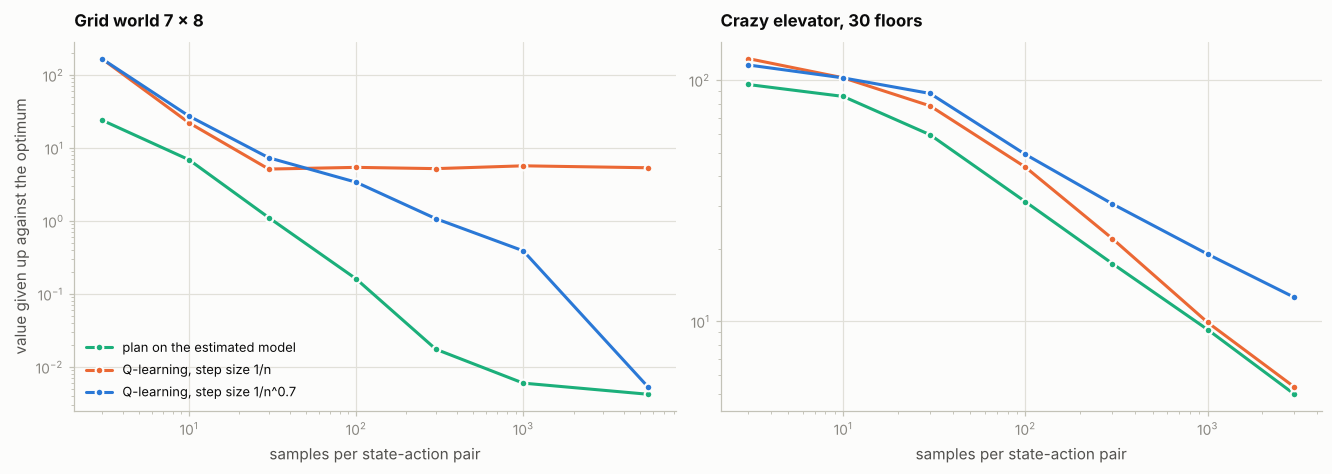

In [7]:
def compare_on_samples(m, sample_sizes, n_repeats=10):
    sc = ml.PolicyScorer(m)
    planned = [np.mean([sc(ml.policy_iteration(ml.empirical_model(m, n, seed=1000 * n + k)).Q)["value_gap"][0] for k in range(n_repeats)]) for n in sample_sizes]
    out = {"plan on the estimated model": planned}
    for label, schedule in (("Q-learning, step size 1/n", ml.harmonic()), ("Q-learning, step size 1/n^0.7", ml.polynomial(0.7))):
        run = ml.synchronous_q_learning(m, max(sample_sizes), alpha=schedule, n_runs=n_repeats, seed=0, scorer=sc, n_checkpoints=80)
        out[label] = [run.history["value_gap"][np.abs(run.steps - n).argmin()].mean() for n in sample_sizes]
    return pd.DataFrame(out, index=pd.Index(sample_sizes, name="samples per state-action pair"))


grid_samples = compare_on_samples(mdp, [3, 10, 30, 100, 300, 1000, 5600])
elevator_samples = compare_on_samples(ml.crazy_elevator(30), [3, 10, 30, 100, 300, 1000, 3000])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, data, title in ((axes[0], grid_samples, "Grid world 7 × 8"), (axes[1], elevator_samples, "Crazy elevator, 30 floors")):
    for (label, column), colour in zip(data.items(), [mp.SERIES[2], mp.SERIES[1], mp.SERIES[0]]):
        ax.plot(data.index, np.maximum(column, 2e-3), "o-", color=colour, markersize=5, label=label)
    ax.set(xscale="log", yscale="log", xlabel="samples per state-action pair", title=title)
axes[0].set_ylabel("value given up against the optimum")
axes[0].legend(loc="lower left", fontsize=8.5)
mp.savefig(fig, "09_same_samples")
grid_samples

In [8]:
n_2014 = grid_samples.loc[5600, "Q-learning, step size 1/n"]
enough = grid_samples.index[(grid_samples["plan on the estimated model"] < n_2014).values.argmax()]
display(Markdown(
    f"On the grid world, planning on a model estimated from **{enough} samples per pair** already beats what the 2014 learner "
    f"achieved with 5,600 (a loss of {grid_samples.loc[enough, 'plan on the estimated model']:.2f} against {n_2014:.2f}). "
    f"With 100 samples per pair the planned policy loses {grid_samples.loc[100, 'plan on the estimated model']:.2f}."
))
elevator_samples

On the grid world, planning on a model estimated from **30 samples per pair** already beats what the 2014 learner achieved with 5,600 (a loss of 1.12 against 5.38). With 100 samples per pair the planned policy loses 0.16.

,plan on the estimated model,"Q-learning, step size 1/n","Q-learning, step size 1/n^0.7"
samples per state-action pair,,,
3,95.96,122.95,115.66
10,85.63,102.28,102.19
30,59.38,78.22,88.07
100,31.35,43.62,49.25
300,17.37,22.05,30.71
1000,9.25,9.91,19.01
3000,4.99,5.34,12.57


On the grid world the difference is one to two orders of magnitude in data. The estimated model
captures at once what Q-learning has to discover by letting values seep from cell to cell: once
the frequencies say that a move leads to a pit one time in ten, the planner draws every
consequence of that immediately. Q-learning's problem on this world was never a lack of
information in its samples.

On the elevator the model-based route is also ahead, but not by much, and the reason is the one
from notebook 5. There the difficulty is statistical. Telling thirty nearly equal buttons apart
takes many samples however they are used, and the estimated model is as noisy as the estimated
values.

The report's summary said that "Q-learning took orders of magnitude more iterations and more time
than either value or policy-iteration". For the grid world, most of that gap did not come from
having to learn from samples. It came from how the samples were used.

## Summary

* Q-learning learns the policy that is best when executed exactly; the SARSA family learns the
  policy that is best for an agent that keeps exploring. On the report's grid world these differ
  precisely in the wait-at-the-wall cells: waiting next to a pit is only safe with a steady hand.
* Expected SARSA does everything SARSA does with far less noise.
* Double Q-learning is slow here, because overestimation is not what ails these learners.
* Remembering transitions and replaying them (Dyna-Q) makes experience go several times further.
* Planning on a model estimated from the samples is the most efficient use of them by a wide
  margin on the grid world: a few dozen samples per pair do better than the 5,600 the 2014 learner
  consumed.

**References.** G. Rummery and M. Niranjan, "On-line Q-learning using connectionist systems", 1994
(SARSA). H. van Seijen et al., "A theoretical and empirical analysis of Expected Sarsa", 2009.
H. van Hasselt, "Double Q-learning", 2010. R. Sutton, "Integrated architectures for learning,
planning, and reacting based on approximating dynamic programming", 1990 (Dyna).

Next: [10 · Deep Q-networks](10_deep_q_networks.ipynb).